In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [4]:
# Load data set
rev_df = pd.read_csv(r"C:\Users\HP\OneDrive\Documents\AMDARI\Montra Hospitality Project\Data\Initial Merged Data\merged_data.csv")

### Dataset overview

In [5]:
rev_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   review_id        35000 non-null  int64  
 1   booking_id       35000 non-null  int64  
 2   guest_id         35000 non-null  int64  
 3   hotel_id         35000 non-null  int64  
 4   review_text      35000 non-null  object 
 5   rating_score     35000 non-null  float64
 6   review_date      35000 non-null  object 
 7   sentiment_label  35000 non-null  object 
 8   room_type        35000 non-null  object 
 9   booking_channel  35000 non-null  object 
 10  check_in_date    35000 non-null  object 
 11  check_out_date   35000 non-null  object 
 12  total_amount     35000 non-null  float64
 13  stay_duration    35000 non-null  int64  
 14  customer_type    35000 non-null  object 
 15  loyalty_status   35000 non-null  object 
 16  country          35000 non-null  object 
 17  previous_sta

In [6]:

print(rev_df.shape)


(35000, 22)


In [7]:
rev_df.head()

,review_id,booking_id,guest_id,hotel_id,review_text,rating_score,review_date,sentiment_label,room_type,booking_channel,...,total_amount,stay_duration,customer_type,loyalty_status,country,previous_stays,hotel_name,location,star_rating,total_rooms
0,1,1,6699,18,The overall price was fair for what we paid. M...,3.2,2025-06-02,neutral,Suite,Direct Website,...,296.44,1,Leisure,Unknown,France,4,The Aberdeen Grand,Aberdeen,4,118
1,2,2,11380,23,The room was nothing out of the ordinary for w...,4.0,2025-01-22,positive,Deluxe,Corporate Portal,...,483.56,4,Business,Gold,Germany,4,Nottingham Park Hotel,Nottingham,4,95
2,3,3,4812,13,"Unfortunately, the pool was outdated — it clea...",1.9,2025-03-13,negative,Executive,Travel Agent,...,415.59,2,Business,Unknown,Ireland,4,The London Boutique,London,4,231
3,4,4,982,12,We were disappointed that the neighborhood was...,2.2,2026-03-18,negative,Family Room,Airbnb,...,601.18,3,Leisure,Unknown,Nigeria,0,Manchester Metropolitan,Manchester,3,101
4,5,5,615,5,The room service was standard hotel fare for w...,3.3,2025-03-03,neutral,Deluxe,Expedia,...,603.85,5,Group,Unknown,United States,9,Glasgow Metropolitan,Glasgow,4,214


In [8]:
rev_df.describe()

,review_id,booking_id,guest_id,hotel_id,rating_score,total_amount,stay_duration,previous_stays,star_rating,total_rooms
count,35000.000000,35000.000000,35000.000000,35000.000000,35000.000000,35000.000000,35000.000000,35000.000000,35000.000000,35000.000000
mean,17500.500000,17500.500000,5984.449571,12.973943,3.027429,466.057135,2.954514,2.108143,3.714743,173.610286
std,10103.774047,10103.774047,3470.140340,7.190291,0.931849,315.050703,1.503233,2.252292,0.718501,62.912423
min,1.000000,1.000000,1.000000,1.000000,1.000000,76.530000,1.000000,0.000000,3.000000,71.000000
25%,8750.750000,8750.750000,2957.000000,7.000000,2.400000,241.357500,2.000000,0.000000,3.000000,116.000000
50%,17500.500000,17500.500000,6002.000000,13.000000,3.000000,379.590000,3.000000,2.000000,4.000000,197.000000
75%,26250.250000,26250.250000,8986.000000,19.000000,3.700000,599.495000,4.000000,4.000000,4.000000,224.000000
max,35000.000000,35000.000000,11999.000000,25.000000,5.000000,2447.180000,7.000000,12.000000,5.000000,265.000000


- The distribution of total amount is skewed to the right, most amount are low with a few amount pulling the mean to the right.
- Most of the hotels have more rooms with only a few having fewer number of rooms.

In [9]:
# Checking for missing values
rev_df.isnull().sum()

review_id          0
booking_id         0
guest_id           0
hotel_id           0
review_text        0
rating_score       0
review_date        0
sentiment_label    0
room_type          0
booking_channel    0
check_in_date      0
check_out_date     0
total_amount       0
stay_duration      0
customer_type      0
loyalty_status     0
country            0
previous_stays     0
hotel_name         0
location           0
star_rating        0
total_rooms        0
dtype: int64

In [10]:
# Checking for duplicates
rev_df.duplicated().sum()

np.int64(0)

#### Review volume analysis
- To determine the number of reviews over time and identify review trends.

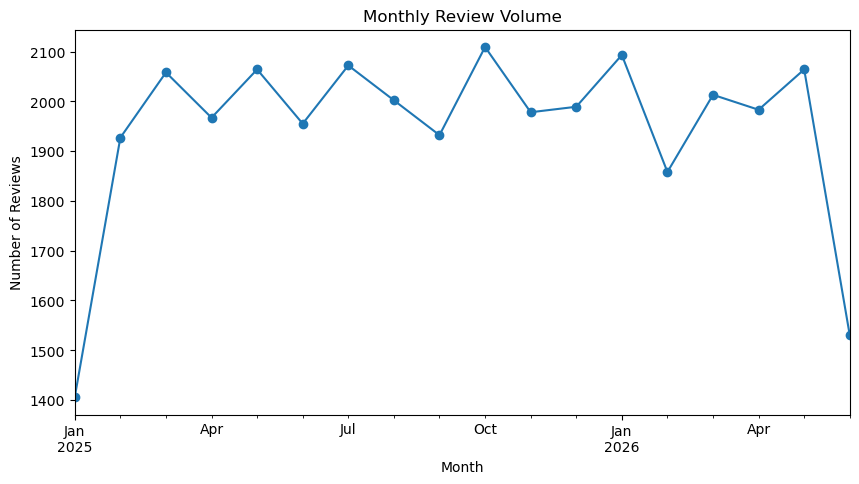

In [11]:
# Monthly Review trend

# Convert dates
rev_df['review_date'] = pd.to_datetime(rev_df['review_date'])

# Monthly review volume
monthly_reviews = rev_df.groupby(
    rev_df['review_date'].dt.to_period('M')
).size()

monthly_reviews.plot(
    figsize=(10,5),
    marker='o'
)

plt.title('Monthly Review Volume')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.show()

- Across the review period there was a similar trend in generated reviews with the highest review in October 2025 and the lowest in February 2026.

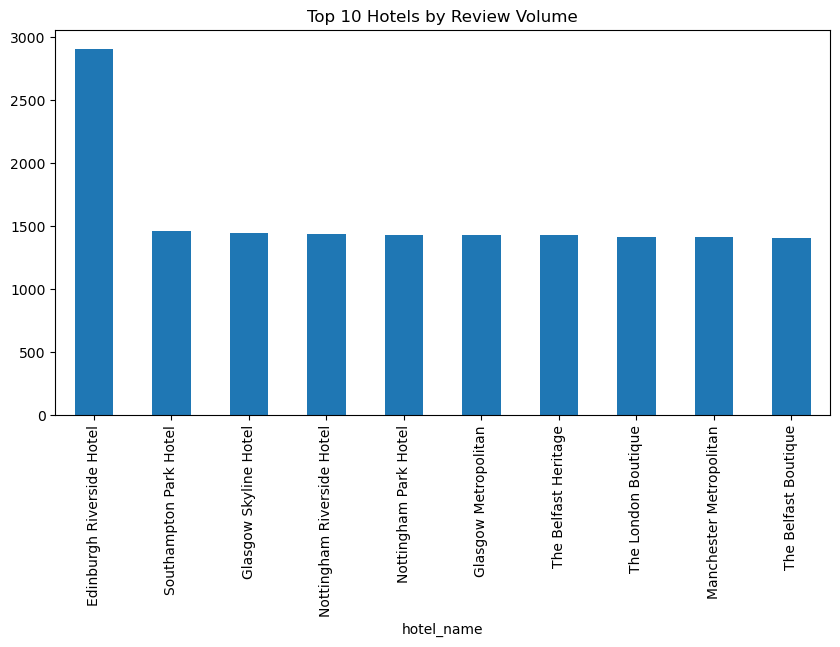

In [12]:
# Reviews by hotel

hotel_reviews = rev_df['hotel_name'].value_counts()

hotel_reviews.head(10).plot(
    kind='bar',
    figsize=(10,5)
)

plt.title('Top 10 Hotels by Review Volume')
plt.show()

- The highest number of reviews came from the Edinburgh Riverside Hotel.

count    35000.000000
mean         3.027429
std          0.931849
min          1.000000
25%          2.400000
50%          3.000000
75%          3.700000
max          5.000000
Name: rating_score, dtype: float64


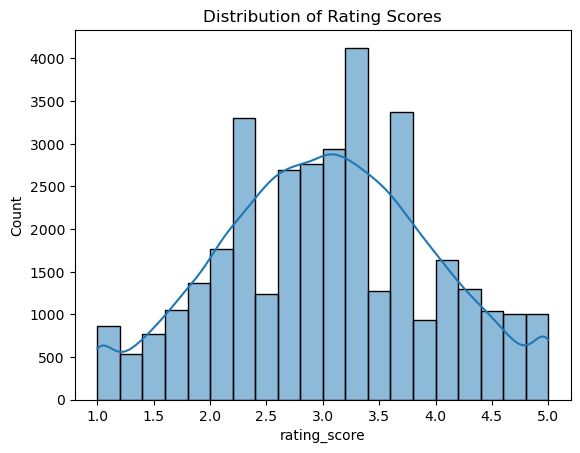

In [13]:
# Rating distribution

print(rev_df['rating_score'].describe())

sns.histplot(
    rev_df['rating_score'],
    bins=20,
    kde=True
)

plt.title('Distribution of Rating Scores')
plt.show()

- Overall rating follows a normal distribution, with most ratings around 3.3.

sentiment_label
neutral     13355
positive    11782
negative     9863
Name: count, dtype: int64


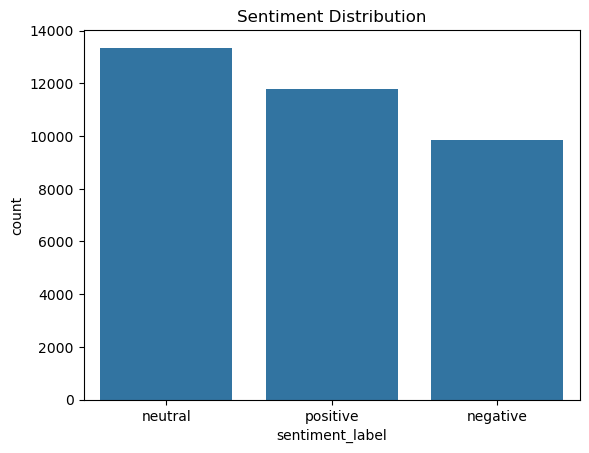

In [14]:
# Sentiment distribution

sentiment_counts = rev_df['sentiment_label'].value_counts()

print(sentiment_counts)

sns.countplot(
    data=rev_df,
    x='sentiment_label'
)

plt.title('Sentiment Distribution')
plt.show()

- Most guests had a neutral sentiment towards their stay.

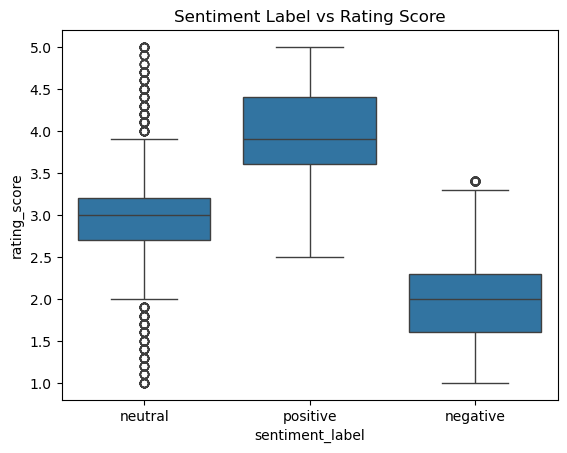

In [15]:
# Sentiments vs Ratings

sns.boxplot(
    data=rev_df,
    x='sentiment_label',
    y='rating_score'
)

plt.title('Sentiment Label vs Rating Score')
plt.show()

- Ratings appears to be directly related to sentiments with guests with high sentiment label also giving higher ratings and guests with negative sentiment labels giving lower rating.
- There are some outliers in rating scores from guests with neutral sentiments as some of their ratings were not related to their sentiments.

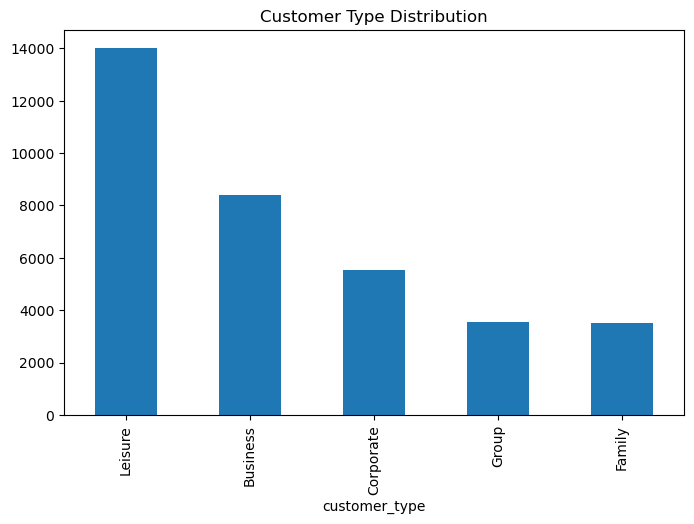

In [16]:
# Customer type distribution

rev_df['customer_type'].value_counts().plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Customer Type Distribution')
plt.show()

- Most guests came in for leisure.

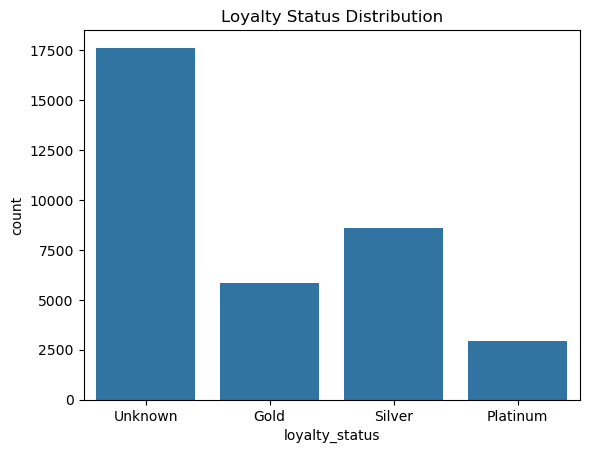

In [17]:
# Loyalty status distribution

sns.countplot(
    data=rev_df,
    x='loyalty_status'
)

plt.title('Loyalty Status Distribution')
plt.show()

- Loyalty status of most guests were not known but among the known loyalty status Silver ranks top.

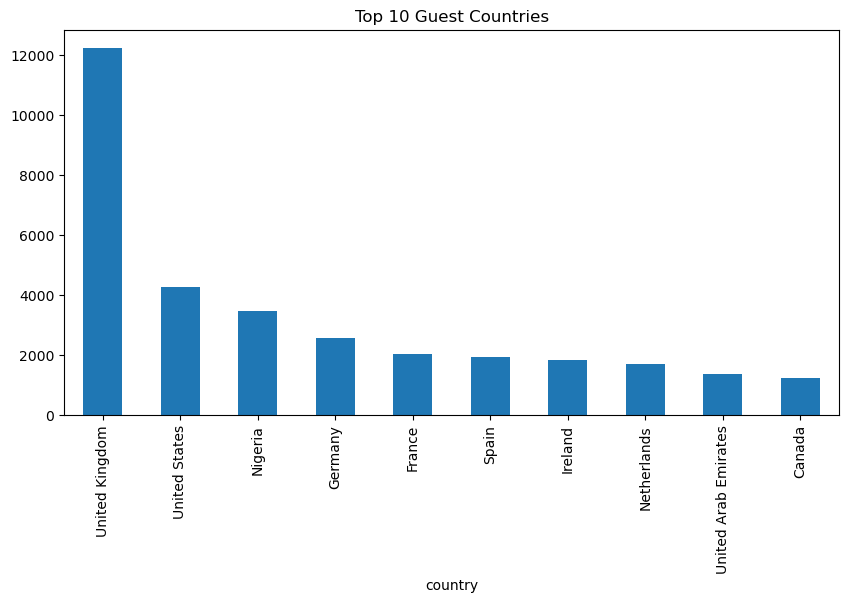

In [18]:
# Top 10 guest countries

top_countries = rev_df['country'].value_counts().head(10)

top_countries.plot(
    kind='bar',
    figsize=(10,5)
)

plt.title('Top 10 Guest Countries')
plt.show()

- Most guests staying at the hotels were from the United Kingdom.

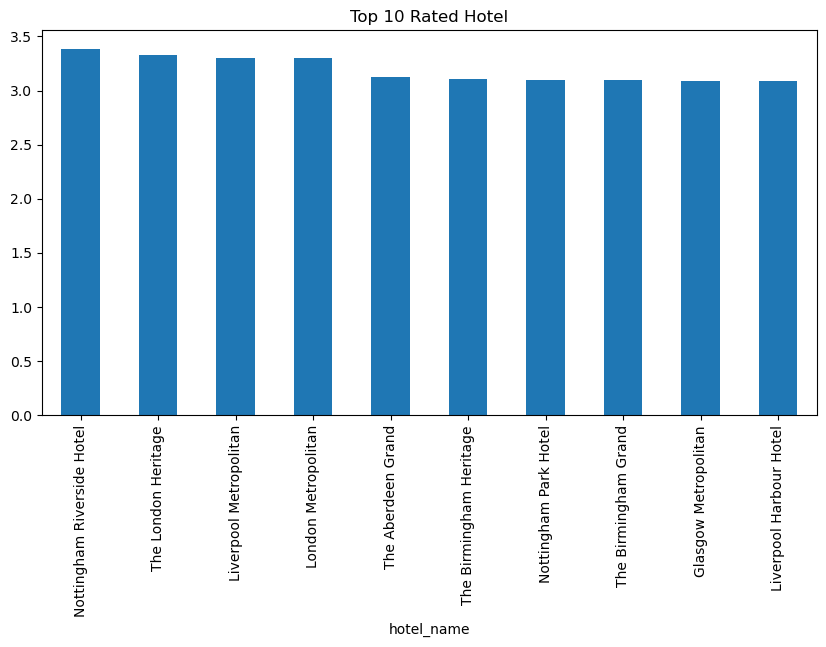

In [19]:
# Hotel performance rating

hotel_rating = rev_df.groupby('hotel_name')['rating_score'].mean()

top_hotel = hotel_rating.sort_values(
    ascending=False
).head(10)

top_hotel.plot(
    kind='bar',
    figsize=(10,5),
)

plt.title('Top 10 Rated Hotel')
plt.show()

- The hotel with the highest rating is the Notingham Riverside hotel.

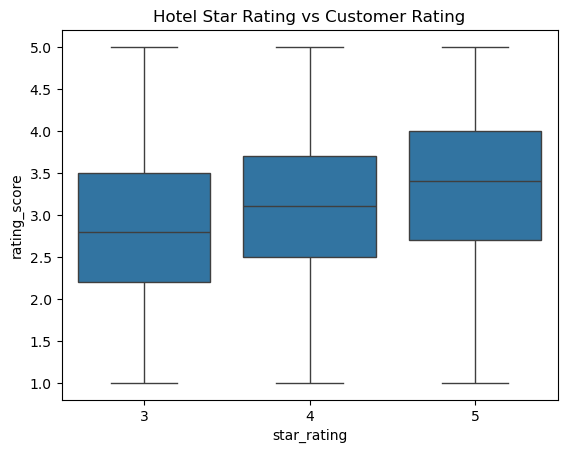

In [20]:
# Hotel star rating vs customer rating

sns.boxplot(
    data=rev_df,
    x='star_rating',
    y='rating_score'
)

plt.title('Hotel Star Rating vs Customer Rating')
plt.show()

- There is a direct relationship between the hotel star rating and guest rating.

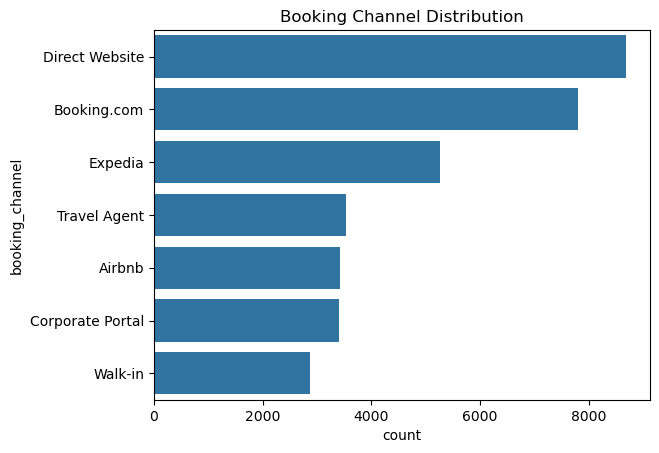

In [21]:
# Booking channel distribution

sns.countplot(
    data=rev_df,
    y='booking_channel',
    order=rev_df['booking_channel'].value_counts().index
)

plt.title('Booking Channel Distribution')
plt.show()

- Most booking were done directly on hotel website.

booking_channel
Airbnb              3.028689
Booking.com         3.033850
Corporate Portal    3.033744
Direct Website      3.021628
Expedia             3.035577
Travel Agent        3.013347
Walk-in             3.020870
Name: rating_score, dtype: float64


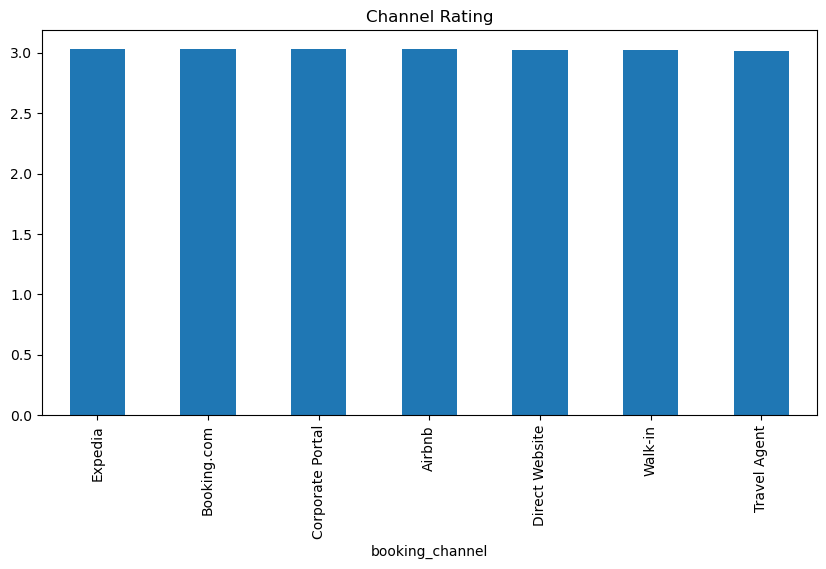

In [22]:
# Rating by booking channel

channel_rating = rev_df.groupby(
    'booking_channel'
)['rating_score'].mean()

top_rated = channel_rating.sort_values(
    ascending=False
)

print(channel_rating)

top_rated.plot(
    kind='bar',
    figsize=(10,5),
)

plt.title('Channel Rating')
plt.show()

- Booking channel did not appear to have much influence on guest ratings.

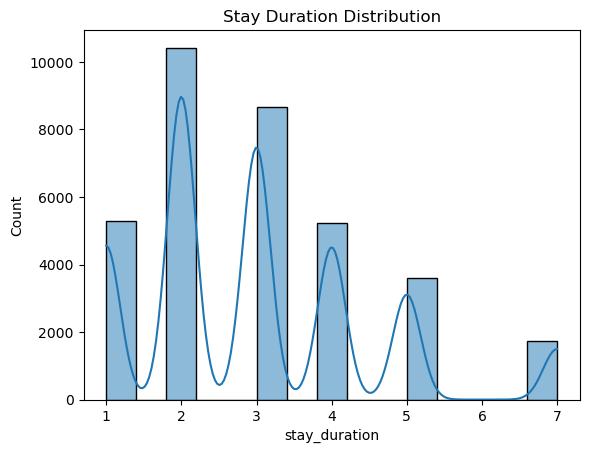

In [23]:
# Stay duration distribution

sns.histplot(
    rev_df['stay_duration'],
    bins=15,
    kde=True
)

plt.title('Stay Duration Distribution')
plt.show()

- Most guests tend to prefer to stay for 2 days.

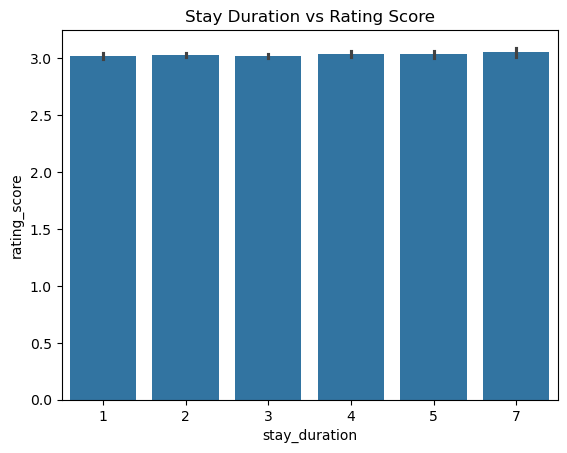

In [24]:
# Stay duration vs Rating

sns.barplot(
    data=rev_df,
    x='stay_duration',
    y='rating_score'
)

plt.title('Stay Duration vs Rating Score')
plt.show()

- There appears to be a direct relationship between stay duration and rating score, with guests staying longer providing the highest ratings.

In [25]:
# Booking amount distribution

rev_df['total_amount'].describe()

count    35000.000000
mean       466.057135
std        315.050703
min         76.530000
25%        241.357500
50%        379.590000
75%        599.495000
max       2447.180000
Name: total_amount, dtype: float64

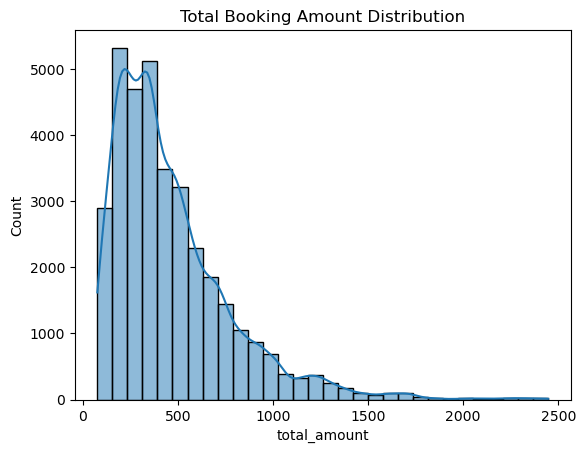

In [26]:
sns.histplot(
    rev_df['total_amount'],
    bins=30,
    kde=True
)

plt.title('Total Booking Amount Distribution')
plt.show()

- Amount for most rooms were low with only a few on the high side.

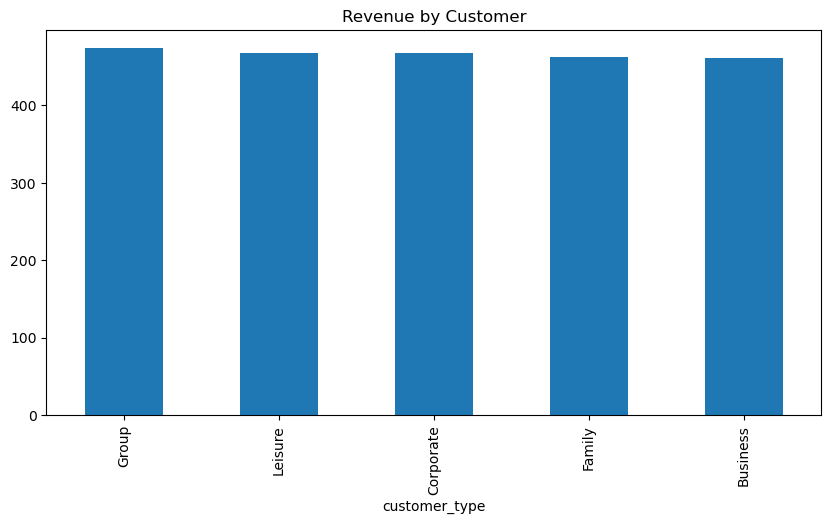

In [27]:
# Revenue by customer type

rev_cust = rev_df.groupby(
    'customer_type'
)['total_amount'].mean().sort_values(
    ascending=False
)

rev_cust.plot(
    kind='bar',
    figsize=(10,5),
)

plt.title('Revenue by Customer')
plt.show()

- Revenue generated by customer group seem to be similar across customer group

In [28]:
numeric_cols = [
    'rating_score',
    'total_amount',
    'stay_duration',
    'previous_stays',
    'star_rating',
    'total_rooms'
]

corr_matrix = rev_df[numeric_cols].corr()

corr_matrix.describe()

,rating_score,total_amount,stay_duration,previous_stays,star_rating,total_rooms
count,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000
mean,0.212376,0.292735,0.296006,0.169672,0.262581,0.246436
std,0.391918,0.459033,0.456516,0.406845,0.396121,0.401540
min,0.003131,-0.005431,0.001769,-0.010158,-0.010158,-0.005431
25%,0.007447,-0.002379,0.003949,0.002925,-0.002720,0.001760
50%,0.041111,0.006343,0.009222,0.008334,0.091781,0.038110
75%,0.154787,0.567419,0.567528,0.009884,0.350170,0.323165
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


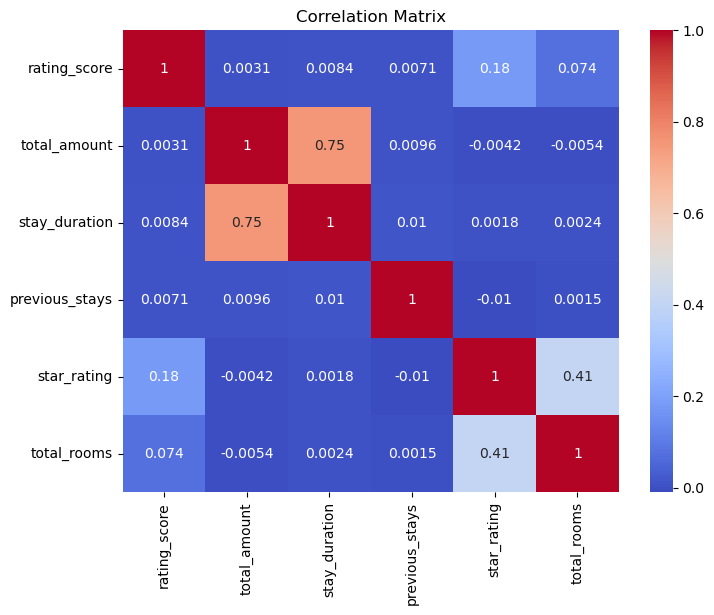

In [29]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Matrix')
plt.show()

- The highest correlation with guest rating is the hotel star rating. 

In [30]:
# Text character length

rev_df['review_length'] = rev_df['review_text'].astype(str).apply(len)

rev_df['review_length'].describe()

count    35000.000000
mean       171.913743
std         39.801050
min         67.000000
25%        143.000000
50%        172.000000
75%        203.000000
max        280.000000
Name: review_length, dtype: float64

- The number of charaters in each review appear to follow a normal distribution

In [31]:
!pip install wordcloud

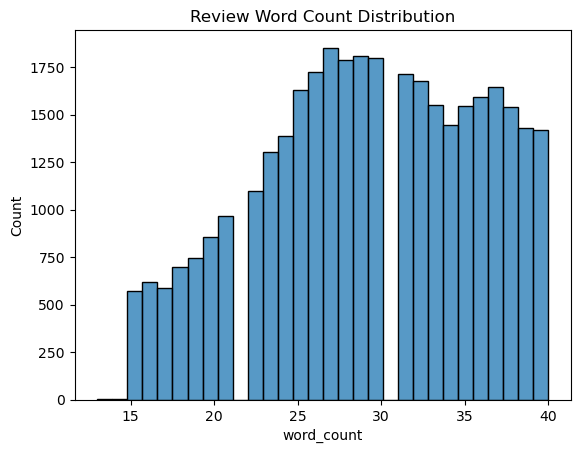

In [32]:
# Word Count

rev_df['word_count'] = rev_df['review_text'].astype(str).apply(
    lambda x: len(x.split())
)

sns.histplot(
    rev_df['word_count'],
    bins=30
)

plt.title('Review Word Count Distribution')
plt.show()

- The number of words in the reviews falls between 25 and 30 words.

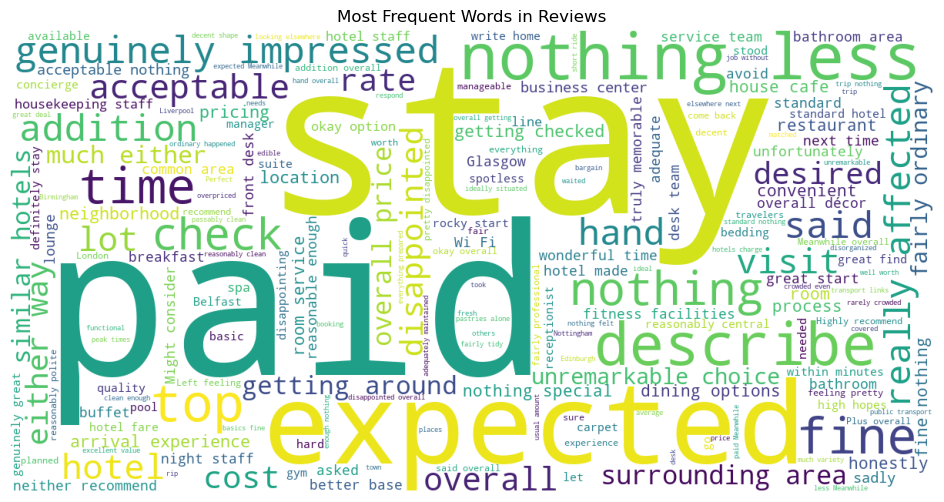

In [33]:
# Word Cloud

from wordcloud import WordCloud

text = " ".join(
    rev_df['review_text'].astype(str)
)

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white'
).generate(text)

plt.figure(figsize=(12,6))

plt.imshow(wordcloud)

plt.axis('off')

plt.title('Most Frequent Words in Reviews')

plt.show()